# Phase 2: Deep Learning Model Training — Dual-Head Multi-Layer Perceptron (PyTorch)

This notebook implements the Phase 2 Deep Learning component of the hybrid AML/DL water quality system.

### Key Architecture & Methodology:
1. **Input Data**: Utilizes the 38 standard-scaled features from `train_scaled.parquet` and `val_scaled.parquet` (StandardScaler fit strictly on training data).
2. **Dual-Head Architecture**:
   - **Shared Representation Trunk**: 3-layer deep MLP with Batch Normalization, GELU activations, and Dropout (0.2) for regularized feature representations.
   - **Regression Head**: Predicts continuous water quality index score (`ccme_values`, 0–100) using Smooth L1 (Huber) loss.
   - **Classification Head**: Predicts categorical water quality grade (`ccme_wqi`, 5 classes: Poor, Marginal, Fair, Good, Excellent) using class-weighted Cross-Entropy loss.
3. **Hardware Acceleration**: Automatic device placement (Apple Silicon GPU via `mps`, CUDA, or CPU fallback).
4. **Artifacts Exported**:
   - Serialized model checkpoint: `deep_learning_mlp_model.pt`
   - Validation predictions: `dl_val_predictions.parquet`
   - Training metrics history: `dl_training_history.csv`
   - Performance figures: `dl_training_curves.png`, `dl_confusion_matrix.png`


## 1. Setup, Environment & Library Imports


In [1]:
import os
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    f1_score,
    confusion_matrix,
    classification_report,
)

# Set random seeds for reproducibility
torch.manual_seed(42)
np.random.seed(42)

# Hardware acceleration: Apple Silicon (mps), CUDA, or CPU
if torch.backends.mps.is_available():
    device = torch.device('mps')
elif torch.cuda.is_available():
    device = torch.device('cuda')
else:
    device = torch.device('cpu')

print(f"PyTorch Version: {torch.__version__}")
print(f"Computation Device: {device}")


PyTorch Version: 2.14.1
Computation Device: mps


## 2. Load Scaled Partitions and Metadata


In [2]:
ROOT_DIR = '.'
for candidate in ['.', '..', '../..']:
    if os.path.exists(os.path.join(candidate, 'data', 'GeneratedOutput')):
        ROOT_DIR = os.path.abspath(candidate)
        break

DATA_DIR = os.path.join(ROOT_DIR, "data", "GeneratedOutput")
train_path = os.path.join(DATA_DIR, "02.Preprocessing&FeatureSelection", "train_scaled.parquet")
val_path   = os.path.join(DATA_DIR, "02.Preprocessing&FeatureSelection", "val_scaled.parquet")
meta_path  = os.path.join(DATA_DIR, "02.Preprocessing&FeatureSelection", "preprocessing_metadata.json")

with open(meta_path) as f:
    metadata = json.load(f)

features = metadata['input_features_ordered']
target_reg = metadata['target_regression']
target_cls = metadata['target_classification_ordinal']

train_df = pd.read_parquet(train_path)
val_df   = pd.read_parquet(val_path)

print(f"Train Partition Rows: {len(train_df):,}  x  {train_df.shape[1]} columns")
print(f"Val Partition Rows  : {len(val_df):,}  x  {val_df.shape[1]} columns")
print(f"Input Features ({len(features)}): {features[:5]} ... {features[-5:]}")


Train Partition Rows: 1,973,731  x  45 columns
Val Partition Rows  : 422,943  x  45 columns
Input Features (38): ['ph', 'temperature_c', 'do_mg_l', 'bod_mg_l', 'ammonia_mg_l'] ... ['quarter', 'month_sin', 'month_cos', 'day_of_year_sin', 'day_of_year_cos']


## 3. Prepare PyTorch Tensors and DataLoaders


In [3]:
BATCH_SIZE = 4096

# Convert features and targets to tensors
X_train_tensor = torch.tensor(train_df[features].to_numpy(dtype=np.float32))
y_train_reg    = torch.tensor(train_df[target_reg].to_numpy(dtype=np.float32)).unsqueeze(1)
y_train_cls    = torch.tensor(train_df[target_cls].to_numpy(dtype=np.int64))

X_val_tensor   = torch.tensor(val_df[features].to_numpy(dtype=np.float32))
y_val_reg      = torch.tensor(val_df[target_reg].to_numpy(dtype=np.float32)).unsqueeze(1)
y_val_cls      = torch.tensor(val_df[target_cls].to_numpy(dtype=np.int64))

train_dataset = TensorDataset(X_train_tensor, y_train_reg, y_train_cls)
val_dataset   = TensorDataset(X_val_tensor, y_val_reg, y_val_cls)

train_loader  = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader    = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)

# Compute inverse class frequencies to weight the classification loss
class_counts = train_df[target_cls].value_counts().sort_index().to_numpy()
total_samples = len(train_df)
num_classes = len(class_counts)
class_weights = total_samples / (num_classes * class_counts.astype(np.float32))
class_weights_tensor = torch.tensor(class_weights, dtype=torch.float32).to(device)

print(f"Train Batches: {len(train_loader)} (Batch size: {BATCH_SIZE})")
print(f"Val Batches  : {len(val_loader)}")
print("Class Frequencies & Weights:")
for idx, (cnt, w) in enumerate(zip(class_counts, class_weights)):
    print(f"  Class {idx} ({metadata.get('ccme_wqi_categories', ['Poor','Marginal','Fair','Good','Excellent'])[idx]}): {cnt:>7,} ({cnt/total_samples*100:5.2f}%)  Weight: {w:.4f}")


Train Batches: 482 (Batch size: 4096)
Val Batches  : 104
Class Frequencies & Weights:
  Class 0 (Poor):  88,609 ( 4.49%)  Weight: 4.4549
  Class 1 (Marginal): 229,848 (11.65%)  Weight: 1.7174
  Class 2 (Fair): 222,114 (11.25%)  Weight: 1.7772
  Class 3 (Good): 718,730 (36.41%)  Weight: 0.5492
  Class 4 (Excellent): 714,430 (36.20%)  Weight: 0.5525


## 4. Define Dual-Head Multi-Layer Perceptron (MLP)


In [4]:
class DualHeadWaterQualityMLP(nn.Module):
    """
    Dual-Head Regularized Multi-Layer Perceptron:
    - Shared Trunk: Extracts rich multi-parameter representations.
    - Regression Head: Predicts continuous CCME Water Quality Index (0-100).
    - Classification Head: Predicts ordinal water quality grade (5 classes).
    """
    def __init__(self, in_features: int, num_classes: int = 5, dropout_rate: float = 0.2):
        super().__init__()
        # Shared Representation Trunk
        self.trunk = nn.Sequential(
            nn.Linear(in_features, 256),
            nn.BatchNorm1d(256),
            nn.GELU(),
            nn.Dropout(dropout_rate),
            
            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.GELU(),
            nn.Dropout(dropout_rate),
            
            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.GELU(),
        )
        
        # Regression Head: Continuous WQI Score
        self.regression_head = nn.Sequential(
            nn.Linear(64, 32),
            nn.GELU(),
            nn.Linear(32, 1)
        )
        
        # Classification Head: 5-Class Categorical Grade
        self.classification_head = nn.Sequential(
            nn.Linear(64, 32),
            nn.GELU(),
            nn.Linear(32, num_classes)
        )

    def forward(self, x: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
        features = self.trunk(x)
        pred_reg = self.regression_head(features)
        pred_cls = self.classification_head(features)
        return pred_reg, pred_cls

model = DualHeadWaterQualityMLP(in_features=len(features), num_classes=5).to(device)
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(model)
print(f"\nTotal Trainable Parameters: {total_params:,}")


DualHeadWaterQualityMLP(
  (trunk): Sequential(
    (0): Linear(in_features=38, out_features=256, bias=True)
    (1): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): GELU(approximate='none')
    (3): Dropout(p=0.2, inplace=False)
    (4): Linear(in_features=256, out_features=128, bias=True)
    (5): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): GELU(approximate='none')
    (7): Dropout(p=0.2, inplace=False)
    (8): Linear(in_features=128, out_features=64, bias=True)
    (9): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): GELU(approximate='none')
  )
  (regression_head): Sequential(
    (0): Linear(in_features=64, out_features=32, bias=True)
    (1): GELU(approximate='none')
    (2): Linear(in_features=32, out_features=1, bias=True)
  )
  (classification_head): Sequential(
    (0): Linear(in_features=64, out_features=32, bias=

## 5. Model Training with Validation Monitoring


In [5]:
NUM_EPOCHS = 8
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
LAMBDA_CLS = 0.5  # Weight for classification loss

criterion_reg = nn.SmoothL1Loss(beta=1.0)
criterion_cls = nn.CrossEntropyLoss(weight=class_weights_tensor)

optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=NUM_EPOCHS, eta_min=1e-5)

history = []
best_val_loss = float('inf')
best_weights = None

output_dir = os.path.join(DATA_DIR, "03.ModelTraining")
os.makedirs(output_dir, exist_ok=True)
checkpoint_path = os.path.join(output_dir, "deep_learning_mlp_model.pt")

print("=" * 85)
print(f"TRAINING DUAL-HEAD MLP ON {device.type.upper()} ({NUM_EPOCHS} EPOCHS)")
print("=" * 85)

for epoch in range(1, NUM_EPOCHS + 1):
    start_t = time.time()
    
    # --- Training Phase ---
    model.train()
    train_loss, train_loss_reg, train_loss_cls = 0.0, 0.0, 0.0
    
    for bx, by_r, by_c in train_loader:
        bx = bx.to(device)
        by_r = by_r.to(device)
        by_c = by_c.to(device)
        
        optimizer.zero_grad()
        p_reg, p_cls = model(bx)
        
        l_reg = criterion_reg(p_reg, by_r)
        l_cls = criterion_cls(p_cls, by_c)
        loss = l_reg + LAMBDA_CLS * l_cls
        
        loss.backward()
        optimizer.step()
        
        train_loss += loss.item() * len(bx)
        train_loss_reg += l_reg.item() * len(bx)
        train_loss_cls += l_cls.item() * len(bx)
        
    train_loss /= len(train_dataset)
    train_loss_reg /= len(train_dataset)
    train_loss_cls /= len(train_dataset)
    
    # --- Validation Phase ---
    model.eval()
    val_loss, val_loss_reg, val_loss_cls = 0.0, 0.0, 0.0
    val_preds_reg, val_preds_cls = [], []
    val_trues_reg, val_trues_cls = [], []
    
    with torch.no_grad():
        for bx, by_r, by_c in val_loader:
            bx = bx.to(device)
            by_r = by_r.to(device)
            by_c = by_c.to(device)
            
            p_reg, p_cls = model(bx)
            l_reg = criterion_reg(p_reg, by_r)
            l_cls = criterion_cls(p_cls, by_c)
            loss = l_reg + LAMBDA_CLS * l_cls
            
            val_loss += loss.item() * len(bx)
            val_loss_reg += l_reg.item() * len(bx)
            val_loss_cls += l_cls.item() * len(bx)
            
            val_preds_reg.append(p_reg.cpu().numpy())
            val_preds_cls.append(p_cls.argmax(dim=-1).cpu().numpy())
            val_trues_reg.append(by_r.cpu().numpy())
            val_trues_cls.append(by_c.cpu().numpy())
            
    val_loss /= len(val_dataset)
    val_loss_reg /= len(val_dataset)
    val_loss_cls /= len(val_dataset)
    scheduler.step()
    
    v_preds_r = np.concatenate(val_preds_reg).flatten()
    v_trues_r = np.concatenate(val_trues_reg).flatten()
    v_preds_c = np.concatenate(val_preds_cls)
    v_trues_c = np.concatenate(val_trues_cls)
    
    val_mae = mean_absolute_error(v_trues_r, v_preds_r)
    val_rmse = np.sqrt(mean_squared_error(v_trues_r, v_preds_r))
    val_r2 = r2_score(v_trues_r, v_preds_r)
    val_acc = accuracy_score(v_trues_c, v_preds_c)
    val_f1_macro = f1_score(v_trues_c, v_preds_c, average='macro')
    
    elapsed = time.time() - start_t
    
    # Save best model
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_weights = model.state_dict().copy()
        torch.save(best_weights, checkpoint_path)
        saved_mark = "★ BEST"
    else:
        saved_mark = ""
        
    history.append({
        'epoch': epoch,
        'train_loss': train_loss,
        'val_loss': val_loss,
        'val_loss_reg': val_loss_reg,
        'val_loss_cls': val_loss_cls,
        'val_mae': val_mae,
        'val_rmse': val_rmse,
        'val_r2': val_r2,
        'val_accuracy': val_acc,
        'val_f1_macro': val_f1_macro,
        'elapsed_sec': elapsed
    })
    
    print(f"Epoch {epoch:2d}/{NUM_EPOCHS:2d} | Train: {train_loss:.4f} | Val: {val_loss:.4f} (Reg: {val_loss_reg:.4f}, Cls: {val_loss_cls:.4f}) | Val MAE: {val_mae:.4f} | RMSE: {val_rmse:.4f} | R²: {val_r2:.4f} | Acc: {val_acc*100:.2f}% | {elapsed:4.1f}s {saved_mark}")

history_df = pd.DataFrame(history)
history_csv_path = os.path.join(output_dir, "dl_training_history.csv")
history_df.to_csv(history_csv_path, index=False)
print(f"\nSaved best checkpoint to: {checkpoint_path}")
print(f"Saved training history to: {history_csv_path}")


TRAINING DUAL-HEAD MLP ON MPS (8 EPOCHS)


Epoch  1/ 8 | Train: 27.2229 | Val: 0.9463 (Reg: 0.8509, Cls: 0.1908) | Val MAE: 1.2510 | RMSE: 1.7224 | R²: 0.9905 | Acc: 91.91% | 14.3s ★ BEST


Epoch  2/ 8 | Train: 1.5761 | Val: 0.7119 (Reg: 0.6374, Cls: 0.1490) | Val MAE: 1.0074 | RMSE: 1.4913 | R²: 0.9929 | Acc: 94.34% | 11.9s ★ BEST


Epoch  3/ 8 | Train: 1.3234 | Val: 0.6521 (Reg: 0.5867, Cls: 0.1308) | Val MAE: 0.9655 | RMSE: 1.3768 | R²: 0.9939 | Acc: 94.52% | 13.1s ★ BEST


Epoch  4/ 8 | Train: 1.1814 | Val: 0.5077 (Reg: 0.4496, Cls: 0.1161) | Val MAE: 0.7533 | RMSE: 1.2313 | R²: 0.9951 | Acc: 95.40% | 12.5s ★ BEST


Epoch  5/ 8 | Train: 1.1133 | Val: 0.5325 (Reg: 0.4767, Cls: 0.1115) | Val MAE: 0.8077 | RMSE: 1.2398 | R²: 0.9951 | Acc: 95.78% | 12.2s 


Epoch  6/ 8 | Train: 1.0523 | Val: 0.5062 (Reg: 0.4512, Cls: 0.1101) | Val MAE: 0.7834 | RMSE: 1.2166 | R²: 0.9953 | Acc: 95.78% | 13.0s ★ BEST


Epoch  7/ 8 | Train: 1.0186 | Val: 0.4897 (Reg: 0.4357, Cls: 0.1080) | Val MAE: 0.7623 | RMSE: 1.1779 | R²: 0.9955 | Acc: 96.05% | 12.3s ★ BEST


Epoch  8/ 8 | Train: 1.0021 | Val: 0.4621 (Reg: 0.4088, Cls: 0.1066) | Val MAE: 0.7056 | RMSE: 1.1557 | R²: 0.9957 | Acc: 96.09% | 12.3s ★ BEST

Saved best checkpoint to: /Users/mayanksharma/Downloads/New_Projects/Semester_5_AML_DL/data/GeneratedOutput/03.ModelTraining/deep_learning_mlp_model.pt
Saved training history to: /Users/mayanksharma/Downloads/New_Projects/Semester_5_AML_DL/data/GeneratedOutput/03.ModelTraining/dl_training_history.csv


## 6. Final Evaluation on Validation Partition


In [6]:
# Load best model weights for final inference
model.load_state_dict(torch.load(checkpoint_path, map_location=device))
model.eval()

val_preds_reg, val_preds_cls = [], []
with torch.no_grad():
    for bx, _, _ in val_loader:
        bx = bx.to(device)
        p_reg, p_cls = model(bx)
        val_preds_reg.append(p_reg.cpu().numpy())
        val_preds_cls.append(p_cls.cpu().numpy())

final_val_pred_reg = np.concatenate(val_preds_reg).flatten()
final_val_pred_cls_logits = np.concatenate(val_preds_cls)
final_val_pred_cls = final_val_pred_cls_logits.argmax(axis=-1)

actual_reg = val_df[target_reg].to_numpy()
actual_cls = val_df[target_cls].to_numpy()

# Save predictions parquet
val_pred_df = pd.DataFrame({
    'actual_ccme_values': actual_reg,
    'pred_ccme_values': final_val_pred_reg,
    'actual_wqi_code': actual_cls,
    'pred_wqi_code': final_val_pred_cls,
})
val_pred_path = os.path.join(output_dir, "dl_val_predictions.parquet")
val_pred_df.to_parquet(val_pred_path, index=False, compression="snappy")
print(f"Saved validation predictions to: {val_pred_path}")

# Regression Metrics
dl_mae = mean_absolute_error(actual_reg, final_val_pred_reg)
dl_rmse = np.sqrt(mean_squared_error(actual_reg, final_val_pred_reg))
dl_r2 = r2_score(actual_reg, final_val_pred_reg)

# Classification Metrics
dl_acc = accuracy_score(actual_cls, final_val_pred_cls)
dl_f1_macro = f1_score(actual_cls, final_val_pred_cls, average='macro')
dl_f1_weighted = f1_score(actual_cls, final_val_pred_cls, average='weighted')

print("\n" + "=" * 65)
print("PHASE 2 DEEP LEARNING (DUAL-HEAD MLP) VALIDATION METRICS")
print("=" * 65)
print(f"  • Regression MAE  : {dl_mae:.4f}")
print(f"  • Regression RMSE : {dl_rmse:.4f}")
print(f"  • Regression R²   : {dl_r2:.6f}")
print(f"  • Classification Accuracy : {dl_acc*100:.2f}%")
print(f"  • Classification F1 Macro : {dl_f1_macro:.4f}")
print(f"  • Classification F1 Weighted : {dl_f1_weighted:.4f}")

categories = ['Poor', 'Marginal', 'Fair', 'Good', 'Excellent']
print("\nClassification Report:")
print(classification_report(actual_cls, final_val_pred_cls, target_names=categories, digits=4))


Saved validation predictions to: /Users/mayanksharma/Downloads/New_Projects/Semester_5_AML_DL/data/GeneratedOutput/03.ModelTraining/dl_val_predictions.parquet

PHASE 2 DEEP LEARNING (DUAL-HEAD MLP) VALIDATION METRICS
  • Regression MAE  : 0.7056
  • Regression RMSE : 1.1557
  • Regression R²   : 0.995716
  • Classification Accuracy : 96.09%
  • Classification F1 Macro : 0.9485
  • Classification F1 Weighted : 0.9611

Classification Report:
              precision    recall  f1-score   support

        Poor     0.8740    0.9749    0.9217     18988
    Marginal     0.9740    0.9337    0.9534     49253
        Fair     0.8894    0.9687    0.9273     47596
        Good     0.9831    0.9378    0.9599    154014
   Excellent     0.9715    0.9887    0.9800    153092

    accuracy                         0.9609    422943
   macro avg     0.9384    0.9608    0.9485    422943
weighted avg     0.9624    0.9609    0.9611    422943



## 7. Performance Visualizations


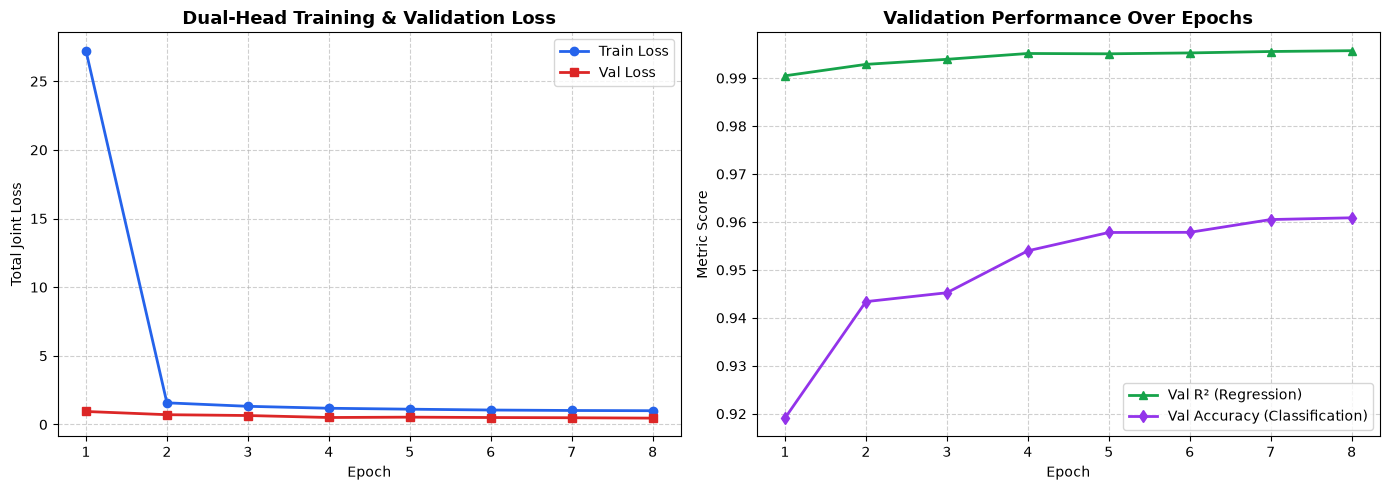

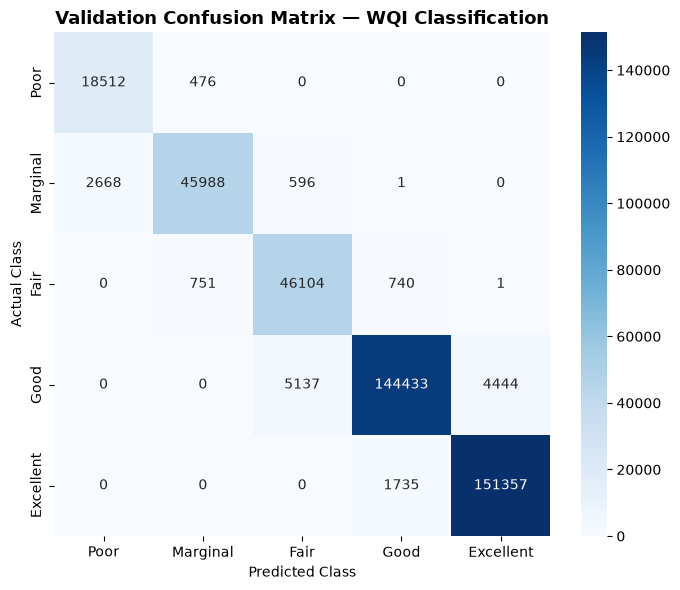

Saved figures to /Users/mayanksharma/Downloads/New_Projects/Semester_5_AML_DL/data/GeneratedOutput/03.ModelTraining:
  • dl_training_curves.png
  • dl_confusion_matrix.png


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Loss curves
axes[0].plot(history_df['epoch'], history_df['train_loss'], label='Train Loss', marker='o', color='#2563eb', linewidth=2)
axes[0].plot(history_df['epoch'], history_df['val_loss'], label='Val Loss', marker='s', color='#dc2626', linewidth=2)
axes[0].set_title('Dual-Head Training & Validation Loss', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Total Joint Loss')
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.6)

# Plot 2: Validation R² and Accuracy
ax2 = axes[1]
ax2.plot(history_df['epoch'], history_df['val_r2'], label='Val R² (Regression)', marker='^', color='#16a34a', linewidth=2)
ax2.plot(history_df['epoch'], history_df['val_accuracy'], label='Val Accuracy (Classification)', marker='d', color='#9333ea', linewidth=2)
ax2.set_title('Validation Performance Over Epochs', fontsize=13, fontweight='bold')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Metric Score')
ax2.legend()
ax2.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
curves_path = os.path.join(output_dir, "dl_training_curves.png")
plt.savefig(curves_path, dpi=150, bbox_inches='tight')
plt.show()

# Plot 3: Confusion Matrix
cm = confusion_matrix(actual_cls, final_val_pred_cls)
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=categories, yticklabels=categories, ax=ax)
ax.set_title('Validation Confusion Matrix — WQI Classification', fontsize=13, fontweight='bold')
ax.set_xlabel('Predicted Class')
ax.set_ylabel('Actual Class')
plt.tight_layout()
cm_path = os.path.join(output_dir, "dl_confusion_matrix.png")
plt.savefig(cm_path, dpi=150, bbox_inches='tight')
plt.show()

print(f"Saved figures to {output_dir}:")
print(f"  • {os.path.basename(curves_path)}")
print(f"  • {os.path.basename(cm_path)}")


## 8. Hybrid Comparison: Deep Learning MLP vs. Tree Models


In [8]:
ml_history_path = os.path.join(DATA_DIR, "03.ModelTraining", "training_history.csv")
if os.path.exists(ml_history_path):
    ml_hist = pd.read_csv(ml_history_path)
    
    # Add DL row
    dl_summary_row = pd.DataFrame([{
        'model': 'Dual-Head MLP (PyTorch)',
        'train_rows': len(train_df),
        'val_rows': len(val_df),
        'features_count': len(features),
        'train_mae': np.nan,
        'train_rmse': np.nan,
        'train_r2': np.nan,
        'val_mae': dl_mae,
        'val_rmse': dl_rmse,
        'val_r2': dl_r2
    }])
    
    combined_comparison = pd.concat([ml_hist, dl_summary_row], ignore_index=True)
    combined_comparison_path = os.path.join(DATA_DIR, "04.ModelEvaluation", "all_models_comparison.csv")
    combined_comparison.to_csv(combined_comparison_path, index=False)
    
    print("=" * 80)
    print("COMPLETE AML / DL HYBRID MODEL COMPARISON TABLE (VALIDATION SET)")
    print("=" * 80)
    display(combined_comparison[['model', 'val_mae', 'val_rmse', 'val_r2']].round(4))


COMPLETE AML / DL HYBRID MODEL COMPARISON TABLE (VALIDATION SET)


,model,val_mae,val_rmse,val_r2
0,Mean baseline,14.1297,17.6561,-0.0000
1,Random Forest,0.0521,0.2081,0.9999
2,XGBoost,0.1375,0.3740,0.9996
3,Dual-Head MLP (PyTorch),0.7056,1.1557,0.9957
